<a href="https://colab.research.google.com/github/urazovandriy-dotcom/ML_LABS_2026/blob/main/%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%B5_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_ML%D0%B4%D0%B6%D1%83%D0%BD%D1%96%D0%BE%D1%80_%D0%A3%D1%80%D0%B0%D0%B7%D0%BE%D0%B2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Тестове завдання «Прогнозування відтоку клієнтів»

Виконав студет групи 3-10 Уразов Андрій.

Для реалізації завдання було обрано датасет `Credit Card customers`.

Посилання на датасет: https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers


**1. Імпорт бібліотек та завантаження датасету**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakshigoyal7/credit-card-customers")

print("Path to dataset files:", path)

sns.set_theme(style="whitegrid")
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
file_path = os.path.join(path, csv_files[0])
df = pd.read_csv(file_path)
print(f"Файл завантажено: {csv_files[0]}")
print(f"Розмір датасету: {df.shape[0]} рядків, {df.shape[1]} стовпців")
df.head(3)

Using Colab cache for faster access to the 'credit-card-customers' dataset.
Path to dataset files: /kaggle/input/credit-card-customers
Файл завантажено: BankChurners.csv
Розмір датасету: 10127 рядків, 23 стовпців


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998


**2. Первинний огляд даних та EDA**

--- Загальна інформація про датасет ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                   

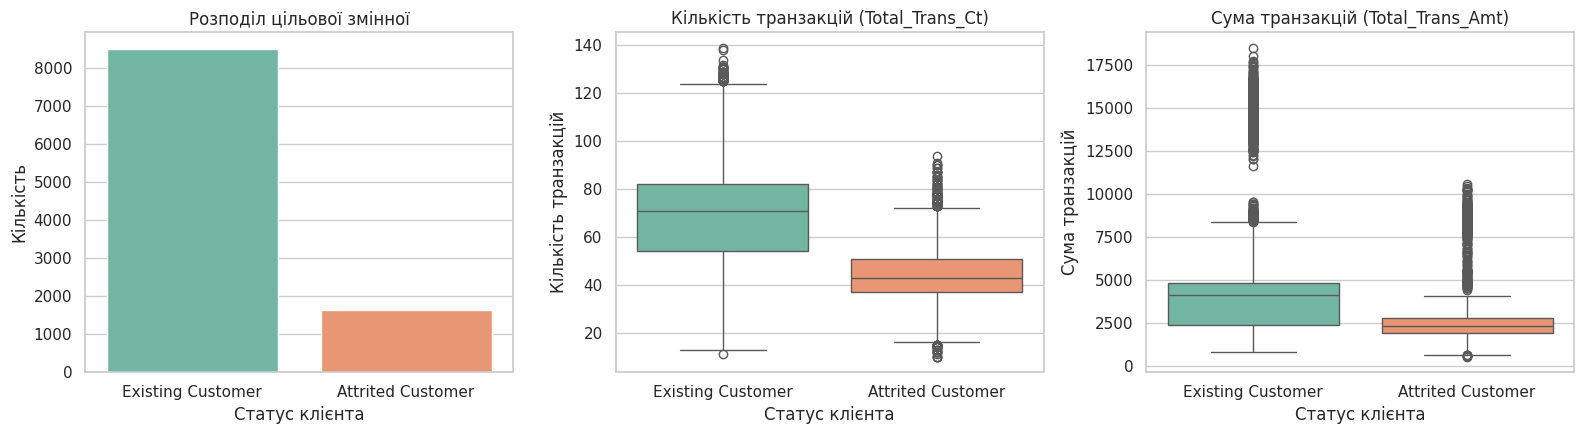

In [2]:
print("--- Загальна інформація про датасет ---")
df.info()
print("\n--- Кількість пропусків у стовпцях ---")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Пропусків не виявлено.")
print(f"\nКількість повних дублікатів: {df.duplicated().sum()}")
print("\n--- Розподіл цільової змінної (Attrition_Flag) ---")
target_counts = df["Attrition_Flag"].value_counts()
target_pct = df["Attrition_Flag"].value_counts(normalize=True) * 100
for cls, cnt in target_counts.items():
    print(f"{cls}: {cnt} ({target_pct[cls]:.2f}%)")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.countplot(data=df, x="Attrition_Flag", hue="Attrition_Flag", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Розподіл цільової змінної")
axes[0].set_xlabel("Статус клієнта")
axes[0].set_ylabel("Кількість")
sns.boxplot(data=df, x="Attrition_Flag", y="Total_Trans_Ct", hue="Attrition_Flag", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Кількість транзакцій (Total_Trans_Ct)")
axes[1].set_xlabel("Статус клієнта")
axes[1].set_ylabel("Кількість транзакцій")
sns.boxplot(data=df, x="Attrition_Flag", y="Total_Trans_Amt", hue="Attrition_Flag", palette="Set2", legend=False, ax=axes[2])
axes[2].set_title("Сума транзакцій (Total_Trans_Amt)")
axes[2].set_xlabel("Статус клієнта")
axes[2].set_ylabel("Сума транзакцій")
plt.tight_layout()
plt.show()

**3. Підготовка даних та стратифіковане розбиття**

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
cols_to_drop = ["CLIENTNUM"] + [col for col in df.columns if col.startswith("Naive_Bayes_Classifier")]
df_clean = df.drop(columns=cols_to_drop).copy()
df_clean["Attrition_Flag"] = df_clean["Attrition_Flag"].map({
    "Existing Customer": 0,
    "Attrited Customer": 1
})
X = df_clean.drop(columns=["Attrition_Flag"])
y = df_clean["Attrition_Flag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = X.select_dtypes(exclude=["object"]).columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols)
    ]
)
print(f"Залишено ознак: {X.shape[1]} (числових: {len(num_cols)}, категоріальних: {len(cat_cols)})")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Частка відтоку у Train: {y_train.mean():.4f}, у Test: {y_test.mean():.4f}")

Залишено ознак: 19 (числових: 14, категоріальних: 5)
Train: (8101, 19), Test: (2026, 19)
Частка відтоку у Train: 0.1607, у Test: 0.1604


**4. Навчання та порівняння моделей (Baseline + Ансамблі)**

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, accuracy_score
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
}
results = []
trained_pipelines = {}
for name, clf in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "Модель": name,
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "F1-score": f1_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Accuracy": accuracy_score(y_test, y_pred)
    })
results_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
print("=== Порівняння базових моделей на тестовій вибірці ===")
display(results_df.round(4))

=== Порівняння базових моделей на тестовій вибірці ===


,Модель,ROC-AUC,F1-score,Precision,Recall,Accuracy
0,XGBoost,0.9911,0.9025,0.9228,0.8831,0.9694
1,Random Forest,0.9851,0.8316,0.9416,0.7446,0.9516
2,Logistic Regression,0.9206,0.6464,0.5341,0.8185,0.8564


**5. Підбір гіперпараметрів (RandomizedSearchCV) та візуалізація результатів**

Навчання та підбір параметрів: Logistic Regression (tuned)...
Навчання та підбір параметрів: Gradient Boosting (tuned)...
Навчання та підбір параметрів: Random Forest (tuned)...
Навчання та підбір параметрів: XGBoost (tuned)...

=== Порівняння налаштованих моделей на тестовій вибірці ===


,Модель,CV ROC-AUC,Test ROC-AUC,F1-score,Precision,Recall
1,Gradient Boosting (tuned),0.9932,0.9926,0.9026,0.9553,0.8554
3,XGBoost (tuned),0.9934,0.9925,0.9077,0.9077,0.9077
2,Random Forest (tuned),0.9870,0.9843,0.8535,0.8953,0.8154
0,Logistic Regression (tuned),0.9256,0.9197,0.6441,0.5309,0.8185



Підібрані гіперпараметри:
- Gradient Boosting (tuned): {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.15}
- XGBoost (tuned): {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
- Random Forest (tuned): {'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}
- Logistic Regression (tuned): {'C': 0.1, 'solver': 'liblinear'}

--- Звіт класифікації для найкращої моделі: Gradient Boosting (tuned) ---
              precision    recall  f1-score   support

Existing (0)       0.97      0.99      0.98      1701
Attrited (1)       0.96      0.86      0.90       325

    accuracy                           0.97      2026
   macro avg       0.96      0.92      0.94      2026
weighted avg       0.97      0.97      0.97      2026



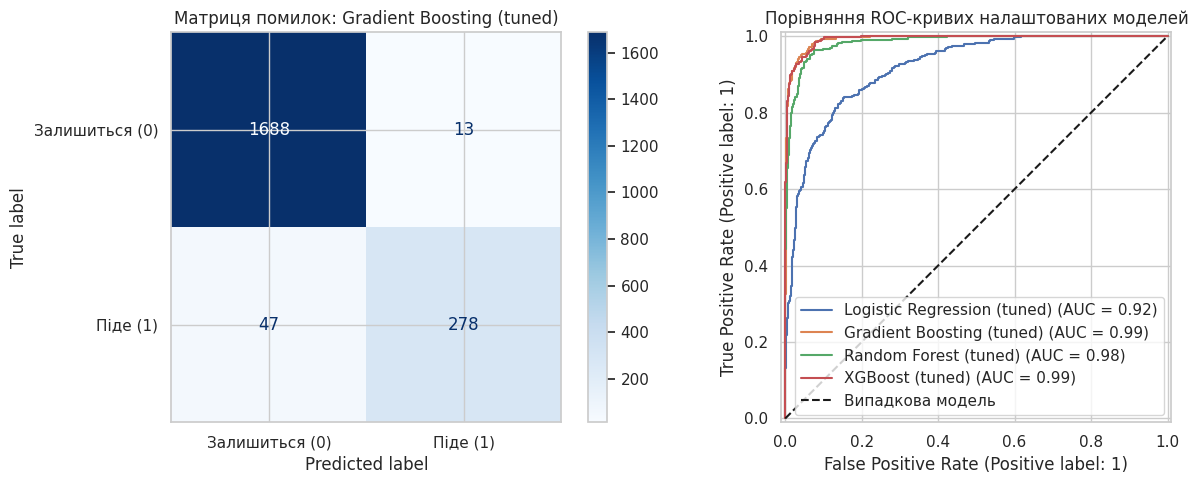

In [5]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score, recall_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
from xgboost import XGBClassifier
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models_config = {
    "Logistic Regression (tuned)": (
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
        {
            "classifier__C": [0.01, 0.1, 1.0, 5.0, 10.0],
            "classifier__solver": ["lbfgs", "liblinear"]
        },
        "grid"
    ),
    "Gradient Boosting (tuned)": (
        GradientBoostingClassifier(random_state=42),
        {
            "classifier__n_estimators": [100, 150, 200],
            "classifier__max_depth": [3, 4, 5],
            "classifier__learning_rate": [0.05, 0.1, 0.15],
            "classifier__subsample": [0.8, 1.0]
        },
        "random"
    ),
    "Random Forest (tuned)": (
        RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
        {
            "classifier__n_estimators": [150, 250],
            "classifier__max_depth": [8, 12, 16, None],
            "classifier__min_samples_split": [2, 5, 10],
            "classifier__min_samples_leaf": [1, 2, 4]
        },
        "random"
    ),
    "XGBoost (tuned)": (
        XGBClassifier(
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            eval_metric="logloss",
            n_jobs=-1
        ),
        {
            "classifier__n_estimators": [150, 200, 300],
            "classifier__max_depth": [3, 4, 5, 6],
            "classifier__learning_rate": [0.03, 0.05, 0.1, 0.15],
            "classifier__subsample": [0.8, 0.9, 1.0],
            "classifier__colsample_bytree": [0.8, 0.9, 1.0]
        },
        "random"
    )
}
tuned_results = []
best_estimators = {}
for name, (clf, params, search_type) in models_config.items():
    print(f"Навчання та підбір параметрів: {name}...")
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    if search_type == "grid":
        search = GridSearchCV(pipe, param_grid=params, scoring="roc_auc", cv=cv, n_jobs=-1)
    else:
        search = RandomizedSearchCV(
            pipe, param_distributions=params, n_iter=8,
            scoring="roc_auc", cv=cv, random_state=42, n_jobs=-1
        )
    search.fit(X_train, y_train)
    best_est = search.best_estimator_
    best_estimators[name] = best_est
    y_pred = best_est.predict(X_test)
    y_proba = best_est.predict_proba(X_test)[:, 1]
    tuned_results.append({
        "Модель": name,
        "CV ROC-AUC": round(search.best_score_, 4),
        "Test ROC-AUC": round(roc_auc_score(y_test, y_proba), 4),
        "F1-score": round(f1_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "Найкращі параметри": {k.replace("classifier__", ""): v for k, v in search.best_params_.items()}
    })
results_tuned_df = pd.DataFrame(tuned_results).sort_values(by="Test ROC-AUC", ascending=False)
print("\n=== Порівняння налаштованих моделей на тестовій вибірці ===")
display(results_tuned_df.drop(columns=["Найкращі параметри"]))
print("\nПідібрані гіперпараметри:")
for _, row in results_tuned_df.iterrows():
    print(f"- {row['Модель']}: {row['Найкращі параметри']}")
best_model_name = results_tuned_df.iloc[0]["Модель"]
best_model = best_estimators[best_model_name]
y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]
print(f"\n--- Звіт класифікації для найкращої моделі: {best_model_name} ---")
print(classification_report(y_test, y_pred_best, target_names=["Existing (0)", "Attrited (1)"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best,
    display_labels=["Залишиться (0)", "Піде (1)"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title(f"Матриця помилок: {best_model_name}")
for name, est in best_estimators.items():
    RocCurveDisplay.from_estimator(est, X_test, y_test, ax=axes[1], name=name)
axes[1].plot([0, 1], [0, 1], "k--", label="Випадкова модель")
axes[1].set_title("Порівняння ROC-кривих налаштованих моделей")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**6. Практичний прогноз для конкретного клієнта (інференс)**

In [7]:
def predict_churn(client_data, model=best_model):
    """
    Приймає словник або DataFrame з ознаками клієнта.
    Повертає прогноз (піде / залишиться) та ймовірність відтоку.
    """
    if isinstance(client_data, dict):
        client_df = pd.DataFrame([client_data])
    else:
        client_df = client_data.copy()
    pred_class = int(model.predict(client_df)[0])
    churn_proba = float(model.predict_proba(client_df)[0, 1])
    status = "ПІДЕ (Attrited Customer)" if pred_class == 1 else "ЗАЛИШИТЬСЯ (Existing Customer)"
    print(f"Прогноз: {status}")
    print(f"Ймовірність відтоку: {churn_proba * 100:.2f}%")
    return pred_class, churn_proba
churned_indices = X_test[(y_test == 1) & (best_model.predict(X_test) == 1)].index
churned_sample = X_test.loc[churned_indices[0]].to_dict()
print("--- Тест 1 (клієнт із групи відтоку) ---")
predict_churn(churned_sample)
custom_client = {
    "Customer_Age": 42,
    "Gender": "M",
    "Dependent_count": 2,
    "Education_Level": "Graduate",
    "Marital_Status": "Married",
    "Income_Category": "$60K - $80K",
    "Card_Category": "Blue",
    "Months_on_book": 36,
    "Total_Relationship_Count": 4,
    "Months_Inactive_12_mon": 1,
    "Contacts_Count_12_mon": 2,
    "Credit_Limit": 12000.0,
    "Total_Revolving_Bal": 1500,
    "Avg_Open_To_Buy": 10500.0,
    "Total_Amt_Chng_Q4_Q1": 0.85,
    "Total_Trans_Amt": 4800,
    "Total_Trans_Ct": 75,
    "Total_Ct_Chng_Q4_Q1": 0.90,
    "Avg_Utilization_Ratio": 0.125
}
print("\n--- Тест 2 (новий умовний клієнт) ---")
predict_churn(custom_client)

--- Тест 1 (клієнт із групи відтоку) ---
Прогноз: ПІДЕ (Attrited Customer)
Ймовірність відтоку: 99.96%

--- Тест 2 (новий умовний клієнт) ---
Прогноз: ЗАЛИШИТЬСЯ (Existing Customer)
Ймовірність відтоку: 0.01%


(0, 0.00012406248022014276)

### **Висновки щодо отриманих результатів**

Під час виконання завдання я проаналізував набір даних **Credit Card Customers** (`10 127` записів із часткою відтоку `16,07%`) та підготував ознаки без витоку даних, вилучивши ідентифікатор `CLIENTNUM`, службові стовпці `Naive_Bayes_Classifier_*` і застосувавши стратифіковане розбиття вибірки всередині `Pipeline`. Замість використання алгоритмів із параметрами за замовчуванням я виконав балансування класів та підбір гіперпараметрів на крос-валідації (`GridSearchCV` і `RandomizedSearchCV`) для чотирьох моделей: **Logistic Regression**, **Random Forest**, **Gradient Boosting** та **XGBoost**. Найвищу якість за метрикою ранжування показав налаштований класичний **Gradient Boosting** (`Test ROC-AUC = 0.9926`, `F1-score = 0.9026`, `Precision = 0.9553`, `Recall = 0.8554`), випередивши **XGBoost** (`Test ROC-AUC = 0.9925`, `F1-score = 0.9077`), **Random Forest** (`0.9843`) та **Logistic Regression** (`0.9197`), допустивши лише `13` хибних спрацьовувань і `47` пропусків на `2026` тестових прикладах. На завершальному етапі я реалізував функцію `predict_churn()`, яка на основі введених параметрів клієнта розраховує ймовірність його відтоку та формує підсумковий прогноз. Загалом побудована модель показала високу точність і може ефективно використовуватися банком для своєчасного виявлення та утримання схильних до відтоку клієнтів.